# 02 · Explore HPD violations
**Dataset:** [Housing Maintenance Code Violations](https://data.cityofnewyork.us/d/wvxf-dwi5), downloaded by inspection date from January 2025 → October 2026, in `data/raw/hpd_violations/`.

**Complaint vs violation:**
- A **complaint** is what a tenant says.
- A **violation** is what an HPD **inspector confirmed** and legally ordered the landlord to fix. It's stronger evidence.

Violations are rated by severity:

| Class | Meaning | Correction deadline |
|---|---|---|
| A | Non-hazardous | 90 days |
| B | Hazardous | 30 days |
| C | Immediately hazardous (no heat, lead paint, rodents, broken locks …) | 24 hours |
| I | Information order | – |

**Questions for this notebook:**
1. How many violations are there, and how severe?
2. What are they about? The text is free-form, so we categorize it with regex.
3. How long do they stay open?
4. Do violations and complaints point at the same buildings?

**Study window: January 1, 2025–October 31, 2026.** Annual comparisons should use January–October in both years. Housing prediction uses six-month histories and four-month outcomes; older figures and reports describe the previous study.

In [1]:
import sys, pathlib
ROOT = pathlib.Path.cwd().parent if pathlib.Path.cwd().name == "notebooks" else pathlib.Path.cwd()
sys.path.insert(0, str(ROOT))

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from src import config, housing as H, preprocess as P
from src.plots import save, ACCENT, MUTED

pd.set_option("display.float_format", "{:,.2f}".format)
pd.set_option("display.max_colwidth", 80)

pluto = H.clean_pluto_table()[["bbl", "is_residential", "unitsres", "yearbuilt"]]   # cleans PLUTO on first use
pluto_bbls = set(pluto["bbl"])
residential_bbls = set(pluto.loc[pluto["is_residential"], "bbl"])

## 1. Size and severity

In [2]:
rows = H.monthly_rows("hpd_violations")
print(f"{rows.sum():,} violations | {rows.index[0]} → {rows.index[-1]}")
cols = ["violationid", "bbl", "apartment", "class", "inspectiondate", "novissueddate", "ordernumber",
        "novdescription", "currentstatus", "violationstatus", "rentimpairing"]
v = H.load("hpd_violations", cols)
v["inspectiondate"] = pd.to_datetime(v["inspectiondate"].astype(str), errors="coerce")
v["year"] = v["inspectiondate"].dt.year
H.overview(v)

1,670,801 violations | 2025-01 → 2026-10


,missing_%,distinct,example
violationid,0.00,1670801,17589649
bbl,0.10,136306,4006330008
apartment,35.70,6287,3R
class,0.00,4,A
inspectiondate,0.00,669,2025-01-01 00:00:00
novissueddate,4.30,470,2025-01-02T00:00:00.000
ordernumber,0.00,331,501
novdescription,0.00,1025445,§ 27-2005 HMC: PROPERLY REPAIR OR REPLACE THE BROKEN OR DEFECTIVE ELECTRIC F...
currentstatus,0.00,21,NOV SENT OUT
violationstatus,0.00,2,Open


Duplicate violation ids: 0


class,A,B,C,I
year,,,,
2025,187346,306214,224515,2687
2026,201323,324842,223682,2981


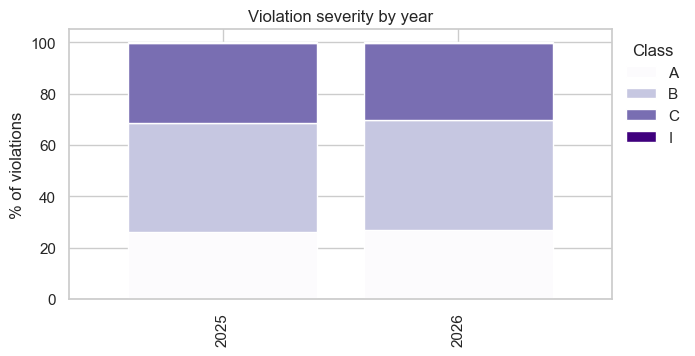

In [3]:
print(f"Duplicate violation ids: {v['violationid'].duplicated().sum():,}")
sev = pd.crosstab(v.loc[v["inspectiondate"].dt.month <= 10, "year"], v.loc[v["inspectiondate"].dt.month <= 10, "class"])
display(sev)
ax = sev.div(sev.sum(axis=1), axis=0).mul(100).plot(kind="bar", stacked=True, figsize=(7, 3.5),
                                                       colormap="Purples", width=0.8)
ax.set(ylabel="% of violations", xlabel="", title="Violation severity by year")
ax.legend(title="Class", bbox_to_anchor=(1, 1), frameon=False)
save(ax.figure, "rent02a_violation_class")

## 2. What are violations about? (regex topic tagging)

In [4]:
print("Example descriptions:")
for t in v["novdescription"].dropna().sample(5, random_state=3):
    print(" -", str(t)[:160])
v["topic"] = H.violation_topic(v["novdescription"])
topics = v["topic"].value_counts(normalize=True).mul(100).round(1)
print(f"\nTagged (not 'other'): {100 - topics.get('other', 0):.1f}%")
pd.crosstab(v["topic"], v["class"], margins=True).sort_values("All", ascending=False)

Example descriptions:


 - (A) § HMC:FILE ANNUAL BEDBUG REPORT IN ACCORDANCE WITH HPD RULE AS DESCRIBED ON THE BACK OF THIS NOTICE OF VIOLATION OR AS DESCRIBED ON HPDS WEBSITE, WWW.NYC.G
 - §27-2107 ADM CODE OWNER FAILED TO FILE A VALID REGISTRATION STATEMENT WITH THE DEPARTMENT AS REQUIRED BY ADM CODE §27-2097 AND IS THEREFORE SUBJECT TO CIVIL PEN
 - § 27-2033 ADM CODE PROVIDE READY ACCESS TO BUILDINGS HEATING SYSTEM DOOR LOCKED AT BASEMENT AT BOILER ROOM
 - § 27-2005, 27-2007, 27-2041.1 HMC, §238, § 309; § 107 (2) ( C) MDL AND 28 RCNY §25-171: REPLACE OR REPAIR THE SELF-CLOSING DOORS THAT IS MISSING OR DEFECTIVE HI
 - § 27-2005 ADM CODE REPAIR THE BROKEN OR DEFECTIVE PLASTERED SURFACES AND PAINT IN A UNIFORM COLOR THE CEILING AND NORTH WALL IN THE BATHROOM LOCATED AT APT 2A, 



Tagged (not 'other'): 91.2%


class,A,B,C,I,All
topic,,,,,
All,408299,689066,501889,71547,1670801
pests,146679,11565,113049,0,271293
paint/plaster,112175,116206,13614,0,241995
doors/locks,10837,57087,122572,80,190576
mold/leaks,49749,118671,17373,0,185793
fire safety,15608,145271,22107,1,182987
other,21289,96113,27861,2496,147759
heat/hot water,1720,4995,94831,1,101547
admin (registration/signs),27082,1613,35,68968,97698


In [5]:
# What's left in 'other'? Shows which regex patterns still need adding.
v.loc[v["topic"] == "other", "novdescription"].astype(str).str[:90].value_counts().head(12).to_frame("count")

,count
novdescription,
§ 27-2005 ADM CODE PROPERLY REPAIR WITH SIMILAR MATERIAL THE BROKEN OR DEFECTIVE WOOD FLOO,17570
§ 27-2005 ADM CODE PROPERLY REPAIR WITH SIMILAR MATERIAL THE BROKEN OR DEFECTIVE VINYL FLO,7718
"§ 27-2010, 2011, 2012 ADM CODE REMOVE THE ACCUMULATION OF REFUSE AND/OR RUBBISH AND MAINTA",7474
"§ 329, M/D LAW AND DEPT. RULES AND REGS. PROVIDE A COMPLETED CERTIFICATE OF INSPECTION VIS",6008
§ 27-2070 ADM CODE PROVIDE AN ADEQUATE SUPPLY OF GAS TO THE FIXTURES AT RANGE IN THE KITCH,4322
§ 27-2005 ADM CODE PROPERLY REPAIR WITH SIMILAR MATERIAL THE BROKEN OR DEFECTIVE CERAMIC F,3820
"§ 27-2005, 2007 ADM CODE REMOVE ALL ENCUMBRANCES CONSISTING OF HOUSEHOLD ITEMS AT PUBLIC H",2984
"§ 27-2021 ADM CODE PROVIDE SUFFICIENT, PROPER AND SEPARATE METAL RECEPTACLES FOR THE DEPOS",2378
§ 27-2005 ADM CODE PROPERLY REPAIR WITH SIMILAR MATERIAL THE BROKEN OR DEFECTIVE VINYL TIL,2136


In [6]:
# Order numbers are a cleaner code for the violation type than the free text
v["ordernumber"].value_counts().head(15).to_frame("violations").join(
    v.groupby("ordernumber")["topic"].agg(lambda s: s.mode().iat[0] if s.notna().any() else None).rename("main topic"))

,violations,main topic
ordernumber,,
501,149067,doors/locks
1507,146564,pests
508,134967,paint/plaster
502,118591,other
530,115475,doors/locks
556,77619,paint/plaster
780,67872,admin (registration/signs)
550,66548,mold/leaks
583,64477,mold/leaks


## 3. How long do violations stay open?

In [3]:
display(v["violationstatus"].value_counts(normalize=True).mul(100).round(1).to_frame("%").T)
open_share = v[v["inspectiondate"].dt.month <= 10].groupby(["year", "class"])["violationstatus"].apply(lambda s: (s == "Open").mean()).unstack()
open_share.mul(100).round(1)

violationstatus,Close,Open
%,54.70,45.30


class,A,B,C,I
year,,,,
2025,37.30,36.30,27.80,48.90
2026,59.60,60.70,48.30,71.60


In [8]:
print(f"Rent-impairing violations: {(v['rentimpairing'] == 'Y').mean():.1%}  "
      "(serious enough that tenants can legally withhold rent)")
v["currentstatus"].value_counts().head(10).to_frame("violations")

Rent-impairing violations: 7.6%  (serious enough that tenants can legally withhold rent)


,violations
currentstatus,
VIOLATION CLOSED,465392
NOV SENT OUT,453365
VIOLATION DISMISSED,447897
NOT COMPLIED WITH,58050
FIRST NO ACCESS TO RE- INSPECT VIOLATION,48279
INFO NOV SENT OUT,40813
NOTICE OF ISSUANCE SENT TO TENANT,40169
CIV14 MAILED,36329
VIOLATION WILL BE REINSPECTED,15909


## 4. Buildings: concentration and overlap with complaints

In [9]:
per_bldg = v.dropna(subset=["bbl"]).groupby("bbl").size()
print(f"Buildings with violations: {len(per_bldg):,}; BBLs matching PLUTO: {H.coverage(v['bbl'], pluto_bbls):.1%}")
display(H.concentration(per_bldg).map("{:.0%}".format).to_frame("share of all violations").T)
complaint_bbls = set(H.load("hpd_complaints", ["bbl"])["bbl"].dropna())
viol_bbls = set(per_bldg.index)
print(f"Buildings with complaints: {len(complaint_bbls):,} | with violations: {len(viol_bbls):,} | "
      f"both: {len(complaint_bbls & viol_bbls):,}")
print(f"Share of complaint buildings that also got a violation: {len(complaint_bbls & viol_bbls) / len(complaint_bbls):.1%}")

Buildings with violations: 136,306; BBLs matching PLUTO: 99.9%


,top 1%,top 5%,top 10%
share of all violations,28%,58%,73%


Buildings with complaints: 77,578 | with violations: 136,306 | both: 54,774
Share of complaint buildings that also got a violation: 70.6%


## Findings

Run the cells above to inspect results for the shared January 2025–October 2026 study. Previous-window metrics are not reused.